# 1. Import Necessary Libaries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 2. Data Collection

In [2]:
college_data = pd.read_csv(filepath_or_buffer="data/college_list.csv")
college_data

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9
...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6


# 3. Data Understanding

# 4. Data Preperation

#### 4.1 Delete Unnessay Featues

In [3]:
X = college_data.drop(labels=["College_Name"], axis=1)
X.sample(5)

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
387,20,204293,76,2.21,9
103,16,162396,65,6.18,8
235,14,105880,48,2.18,9
153,19,144065,77,2.37,9
170,17,41023,52,2.35,6


#### 4.2 Apply Data Transformation Techniques

In [4]:
X_featues = X.columns.tolist()
X_featues

['Student_Faculty_Ratio',
 'Annual_Fees_INR',
 'Placement_Percentage',
 'Average_Package_LPA',
 'Infrastructure_Score']

In [5]:
std_scalar = StandardScaler()
X_scaled = pd.DataFrame(std_scalar.fit_transform(X), columns=X_featues)
X_scaled

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


In [6]:
X_scaled.mean().round(2)

Student_Faculty_Ratio    0.0
Annual_Fees_INR          0.0
Placement_Percentage    -0.0
Average_Package_LPA      0.0
Infrastructure_Score    -0.0
dtype: float64

In [7]:
X_scaled.std().round(2)

Student_Faculty_Ratio    1.0
Annual_Fees_INR          1.0
Placement_Percentage     1.0
Average_Package_LPA      1.0
Infrastructure_Score     1.0
dtype: float64

# 5. Model Building - K means clustering

In [8]:
kmean_cluster = KMeans(n_clusters=3, random_state=12)
kmean_cluster.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",12
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[

In [9]:
kmean_cluster.labels_

array([2, 0, 0, 0, 2, 1, 1, 0, 2, 1, 1, 1, 0, 2, 1, 1, 2, 0, 1, 2, 1, 2,
       2, 0, 1, 1, 2, 0, 0, 0, 0, 1, 1, 2, 2, 1, 1, 0, 2, 1, 1, 1, 1, 0,
       1, 0, 2, 0, 1, 2, 2, 1, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 1, 0, 2, 0,
       1, 1, 2, 0, 2, 1, 0, 0, 1, 2, 1, 0, 0, 2, 1, 2, 0, 1, 1, 1, 1, 2,
       2, 2, 2, 1, 1, 0, 0, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 0, 1, 2, 2,
       0, 2, 2, 0, 2, 0, 2, 2, 2, 2, 0, 1, 2, 2, 2, 0, 2, 2, 1, 0, 0, 0,
       0, 0, 1, 0, 2, 2, 2, 1, 0, 0, 2, 1, 1, 0, 0, 2, 2, 0, 0, 2, 0, 0,
       0, 1, 1, 2, 2, 1, 1, 1, 2, 2, 2, 1, 2, 2, 2, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 0, 2, 2, 2, 1, 2, 0, 0, 1, 2, 2, 1, 2, 2, 2, 0, 2, 0, 2,
       2, 2, 1, 1, 1, 2, 1, 2, 1, 0, 1, 1, 1, 2, 2, 2, 1, 2, 0, 2, 0, 1,
       1, 1, 1, 0, 1, 2, 2, 1, 0, 0, 1, 1, 0, 1, 1, 2, 0, 1, 0, 0, 2, 2,
       0, 0, 2, 2, 1, 2, 2, 0, 1, 0, 1, 1, 0, 2, 0, 1, 1, 1, 2, 2, 0, 1,
       1, 0, 2, 1, 0, 1, 2, 1, 2, 1, 2, 2, 2, 2, 2, 1, 0, 1, 1, 1, 2, 2,
       1, 2, 0, 0, 1, 0, 1, 0, 2, 2, 1, 0, 0, 1, 2,

Level 1 is finished here and put back to the original dataset for further data mining operations

# ================================================================

In [10]:
X["College_level"] = kmean_cluster.labels_
X.sample(5)

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_level
296,20,74238,92,4.04,5,1
488,28,174990,57,7.22,7,0
82,28,31542,74,9.45,7,0
10,28,193551,77,10.38,5,1
58,15,31062,76,11.58,8,0


In [11]:
X.columns.tolist()

['Student_Faculty_Ratio',
 'Annual_Fees_INR',
 'Placement_Percentage',
 'Average_Package_LPA',
 'Infrastructure_Score',
 'College_level']

In [12]:
X.groupby("College_level").agg(["mean", "min", "max"])


Student_Faculty_Ratio         Annual_Fees_INR                 \
                               mean min max            mean    min     max   
College_level                                                                
0                         23.425676  14  29   116224.283784  30404  249536   
1                         20.347305   8  29   143690.473054  31605  248803   
2                         11.767568   8  22   152347.848649  31015  249930   

              Placement_Percentage         Average_Package_LPA               \
                              mean min max                mean   min    max   
College_level                                                                 
0                        70.040541  40  99            6.787973  2.00  11.99   
1                        74.622754  40  99            7.131078  2.01  11.96   
2                        63.091892  40  99            7.028919  2.01  11.91   

              Infrastructure_Score          
                              mean min max  
College_level                               
0                         7.554054   5   9  
1                         3.862275   3   6  
2                         6.621622   3   9

In [13]:
X.groupby("College_level").agg(["mean"])

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
,mean,mean,mean,mean,mean
College_level,,,,,
0,23.425676,116224.283784,70.040541,6.787973,7.554054
1,20.347305,143690.473054,74.622754,7.131078,3.862275
2,11.767568,152347.848649,63.091892,7.028919,6.621622


In [14]:
X.groupby("College_level").agg(["min", "max"])


Student_Faculty_Ratio     Annual_Fees_INR          \
                                min max             min     max   
College_level                                                     
0                                14  29           30404  249536   
1                                 8  29           31605  248803   
2                                 8  22           31015  249930   

              Placement_Percentage     Average_Package_LPA         \
                               min max                 min    max   
College_level                                                       
0                               40  99                2.00  11.99   
1                               40  99                2.01  11.96   
2                               40  99                2.01  11.91   

              Infrastructure_Score      
                               min max  
College_level                           
0                                5   9  
1                                3   6  
2                                3   9

In [15]:
grouped_df = X.groupby("College_level").agg(
    ["mean", "min", "max"]
)

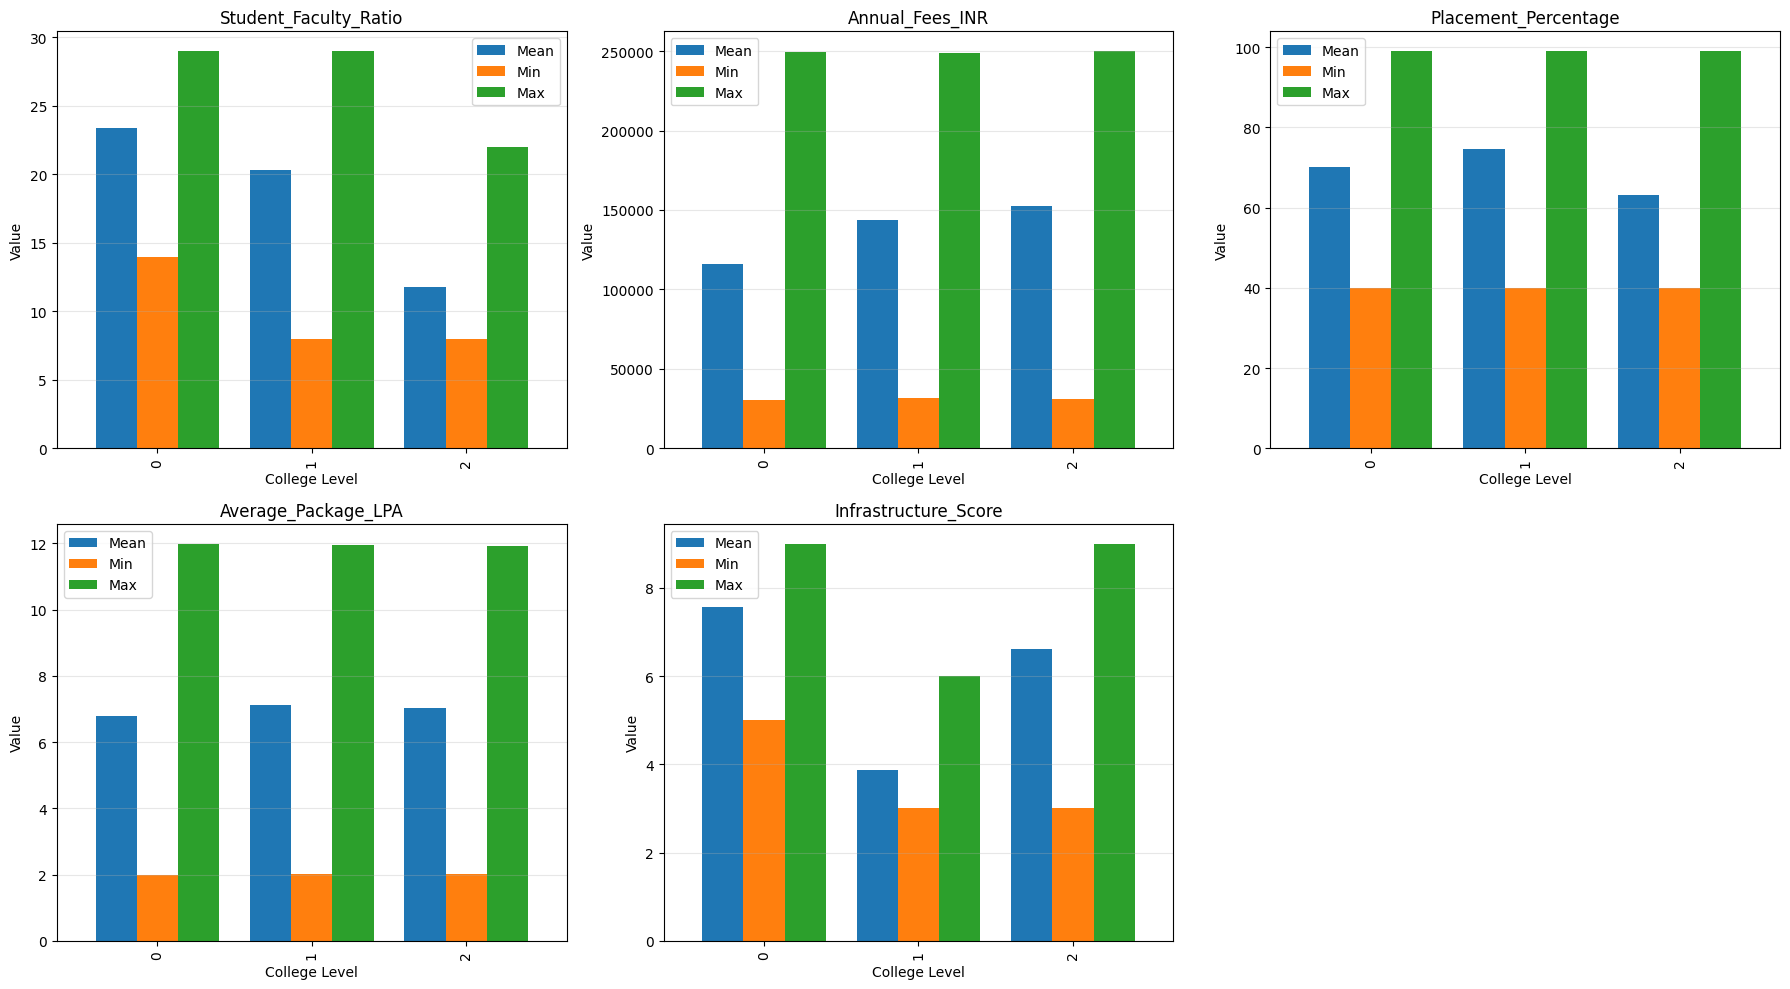

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

features = X.columns.drop("College_level")


for ax, feature in zip(axes.flat, features):

    grouped_df[feature].plot(
        kind="bar",
        ax=ax,
        width=0.8
    )

    ax.set_title(feature)
    ax.set_xlabel("College Level")
    ax.set_ylabel("Value")
    ax.legend(["Mean", "Min", "Max"])
    ax.grid(axis="y", alpha=0.3)

axes.flat[-1].remove()

plt.tight_layout()
plt.show()

In [17]:
cluster_names = {
    0: "Best Colleges",
    1: "Mid-Level Colleges",
    2: "Emerging / Lower-Level Colleges",
}

X["Category"] = X["College_level"].map(cluster_names)

In [18]:
X.sample(5)

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_level,Category
147,9,222714,91,10.38,6,2,Emerging / Lower-Level Colleges
403,19,243630,55,9.35,4,1,Mid-Level Colleges
304,8,95215,67,11.12,4,2,Emerging / Lower-Level Colleges
421,23,216730,87,4.36,4,1,Mid-Level Colleges
307,26,85393,88,6.62,8,0,Best Colleges


# ========================================================

# Level 3: transtion to supervised learning

# ========================================================================

# The Missed Question

### ⭐⭐⭐ How to decide the Optimaal Number of Cluster?

#### WCSS - WithIn Clusters Sum of Squares [ Method used to find the number of clusters ]
![WCSS - Elbow Cruve - Elbow point](data/images/image.png)

---

- a point at which we can't see `maximun decrease` in the `wcss` we take that particulare point and say that is the `optimal number of cluster`

In [19]:
kmean_cluster = KMeans(n_clusters=3, random_state=12)
kmean_cluster.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",12
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[

In [20]:
kmean_cluster.inertia_

1854.1348733872487

##### The K-means algorithm aims to choose `centroids` that minimise the `inertia` or `within-cluster - sum of squares` criterion:

In [21]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=1234)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

In [22]:
wcss

[2500.0,
 2128.174524152106,
 1842.671198109824,
 1630.4255355593134,
 1558.7124859131059,
 1404.5714789757476,
 1282.6375220837544,
 1229.5378438851778,
 1130.029607219633,
 1088.570899449842]

In [23]:
np.mean(wcss)

np.float64(1579.5331095348504)

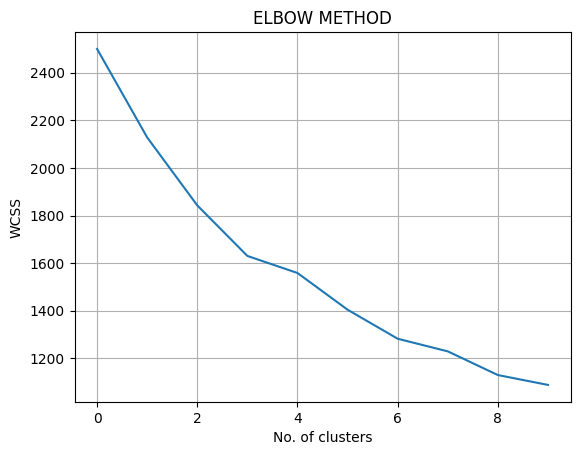

In [24]:
plt.plot(wcss)
plt.grid(True)
plt.title("ELBOW METHOD")
plt.xlabel("No. of clusters")
plt.ylabel("WCSS")
plt.show()

In [25]:
import numpy as np

# 1. Your Y-value (the mean)
mean_wcss = np.mean(wcss)

# 2. Generate the standard X coordinates (0, 1, 2, 3...) matching your list length
x_values = np.arange(len(wcss))

# 3. Calculate the exact respective X value using linear interpolation
# (We flip the arrays [::-1] because np.interp requires the Y-axis data to increase)
respective_x = np.interp(mean_wcss, wcss[::-1], x_values[::-1])

# 4. Print the result
print(f"Respective X value: {respective_x}")



Respective X value: 3.7096675748073475


#### Task
1. Silhoutee Scoree
2. Calinski harabasz socore